# Demo 3 — Counts with exposure: exact and Stan

**Day 2 · Bayesian statistics · Aalborg University 2026** · shown in Lecture B (afternoon)

Run it from top to bottom after the course, then try the list at the end.

**The question (invented data).** A volunteer counts bicycles passing a bike counter in five sessions of **different length**. Two questions:

1. What is **λ, the rate of bikes per minute**?
2. How many bikes will pass in the **next 15 minutes**?

The first is about a rate, the second about a future count; they have different answers.

**Words used** (*slide "Exposure: counts over different lengths of time"*):

- **count** yᵢ: the number of bikes seen in session i;
- **exposure** tᵢ: how long session i lasted, in minutes;
- **rate** λ: expected bikes per minute. Session i is expected to contain λ × tᵢ bikes.

**R used in this notebook.** `tibble()` makes a small table; `|>` reads as "and then"; `mutate()` adds a column; `bind_rows()` stacks tables on top of each other; `count(k)` counts how often each value of `k` occurs. Everything else is base R: `dbeta`, `qbeta`, `pbeta`, `rbeta` (and the same for `binom`, `pois`, `gamma`).

In [1]:
options(tidyverse.quiet = TRUE)
library(tidyverse)   # tibble, dplyr and ggplot2
suppressPackageStartupMessages(library(cmdstanr))   # runs Stan from R
set.seed(2026)
theme_set(theme_minimal(base_size = 13))

## 1. Data

In [2]:
bikes <- tibble(
  session = 1:5,
  minutes = c(10, 15, 5, 20, 10),    # exposure t
  count   = c(23, 31, 9, 44, 18)     # bikes seen y
)
bikes |> mutate(per_minute = count / minutes)

session,minutes,count,per_minute
<int>,<dbl>,<dbl>,<dbl>
1,10,23,2.300000
2,15,31,2.066667
3,5,9,1.800000
4,20,44,2.200000
5,10,18,1.800000


The average count, 25 bikes per session, is **not** a rate: the sessions have different lengths. The data's own estimate of the rate is total bikes / total minutes.

In [3]:
total_count   <- sum(bikes$count)      # 125 bikes
total_minutes <- sum(bikes$minutes)    # 60 minutes

c(mean_count_per_session = mean(bikes$count),
  bikes_per_minute       = total_count / total_minutes)

mean_count_per_session       bikes_per_minute 
             25.000000               2.083333

## 2. Model and exact posterior

*Slides: "The gamma–Poisson update" and "Bikes per minute: prior and posterior".*

- Likelihood: yᵢ | λ ~ Poisson(λ tᵢ), sessions independent, the same λ in every session.
- Prior: λ ~ Gamma(a, b) with shape a = 2 and rate b = 1: mean a / b = 2 bikes per minute, wide. Read it as "about 2 bikes seen in 1 minute" of earlier experience.
- Update rule: λ | y ~ Gamma(a + Σyᵢ, b + Σtᵢ). **Add the total count to a and the total minutes to b.**

In [4]:
a <- 2; b <- 1                       # prior Gamma(shape = 2, rate = 1)
a_post <- a + total_count            # 2 + 125 = 127
b_post <- b + total_minutes          # 1 + 60  = 61

exact <- c(
  mean     = a_post / b_post,
  lower_90 = qgamma(0.05, shape = a_post, rate = b_post),
  upper_90 = qgamma(0.95, shape = a_post, rate = b_post)
)
round(exact, 3)

mean lower_90 upper_90 
   2.082    1.788    2.395

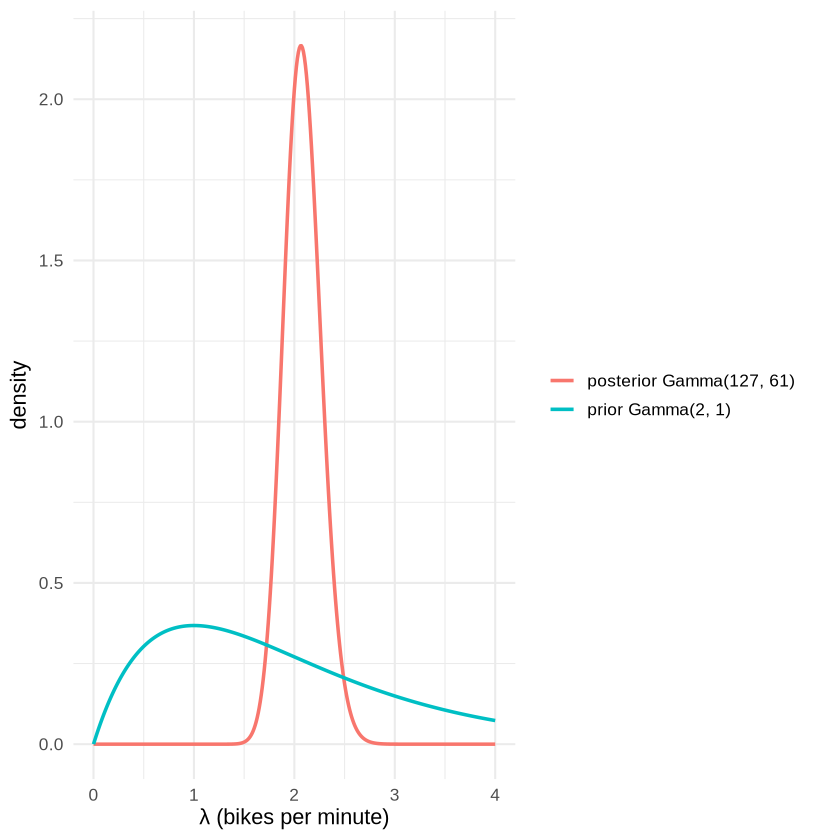

In [5]:
lambda_grid <- seq(0, 4, length.out = 401)

gamma_curves <- bind_rows(
  tibble(lambda = lambda_grid, density = dgamma(lambda_grid, shape = a, rate = b),
         curve = "prior Gamma(2, 1)"),
  tibble(lambda = lambda_grid, density = dgamma(lambda_grid, shape = a_post, rate = b_post),
         curve = "posterior Gamma(127, 61)")
)

ggplot(gamma_curves, aes(x = lambda, y = density, colour = curve)) +
  geom_line(linewidth = 1) +
  labs(x = "λ (bikes per minute)", y = "density", colour = NULL)

## 3. The same model in Stan

*Slide: "The same model in Stan" (afternoon).*

The program is in `models/gamma_poisson_exposure.stan`. Two lines to notice:

- `y ~ poisson(lambda * t);` is the likelihood. The multiplication by `t` is where the exposure enters.
- `generated quantities` runs once per draw: it computes the expected count `mean_new = lambda * t_new` and draws a future count `y_new`, the two-step prediction from the slides.

In [6]:
writeLines(readLines("models/gamma_poisson_exposure.stan"))

// Day 2 demo: counts with exposure (gamma-Poisson) in Stan
// y[i] events counted during t[i] minutes; lambda = events per minute.

data {
  int<lower=1> N;                 // number of counting sessions
  array[N] int<lower=0> y;        // counts
  vector<lower=0>[N] t;           // exposure: minutes counted
  real<lower=0> a;                // prior: Gamma(a, b), shape a, rate b
  real<lower=0> b;
  real<lower=0> t_new;            // exposure for a future session
}

parameters {
  real<lower=0> lambda;           // rate per minute
}

model {
  lambda ~ gamma(a, b);           // prior
  y ~ poisson(lambda * t);        // likelihood: mean = rate x exposure
}

generated quantities {
  real mean_new = lambda * t_new;            // expected count (a rate statement)
  int y_new = poisson_rng(lambda * t_new);   // a future count (a prediction)
}


In [7]:
mod <- cmdstan_model("models/gamma_poisson_exposure.stan")

t_new <- 15    # predict the next 15 minutes
fit <- mod$sample(
  data = list(N = nrow(bikes), y = bikes$count, t = bikes$minutes,
              a = a, b = b, t_new = t_new),
  chains = 4, iter_sampling = 2000, seed = 2026, refresh = 0
)
draws <- fit$draws(format = "draws_df")

Running MCMC with 4 sequential chains...

Chain 1 finished in 0.0 seconds.


Chain 2 Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:



Chain 2 Exception: gamma_lpdf: Random variable is inf, but must be positive finite! (in '/tmp/Rtmpm13Ajv/model-3223624d839.stan', line 18, column 2 to column 23)



Chain 2 If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,



Chain 2 but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.



Chain 2 



... (3 outputs left out)

Chain 3 If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,



Chain 3 but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.



Chain 3 



Chain 3 finished in 0.0 seconds.
Chain 4 finished in 0.0 seconds.

All 4 chains finished successfully.
Mean chain execution time: 0.0 seconds.
Total execution time: 0.7 seconds.



You may see a few *Informational Message* lines at the start of sampling. A few are harmless; Day 3 explains them and how to check that a fit can be trusted.

In [8]:
stan <- c(
  mean     = mean(draws$lambda),
  lower_90 = unname(quantile(draws$lambda, 0.05)),   # unname() drops the label "5%"
  upper_90 = unname(quantile(draws$lambda, 0.95))
)
round(rbind(exact = exact, stan = stan), 3)

,mean,lower_90,upper_90
exact,2.082,1.788,2.395
stan,2.086,1.789,2.402


The small differences come from using a finite number of random draws (Day 3).

## 4. A rate versus a future count

*Slide: "A rate versus a future count".*

For the next 15 minutes there are two different questions:

- the **expected count** 15 × λ: uncertain only because we do not know λ exactly;
- the **future count**: also varies randomly given λ (Poisson), so it is more uncertain.

The exact distribution of the future count is negative binomial (demo 2, section 6); in R `qnbinom(…, size = a_post, prob = b_post / (b_post + t_new))`.

In [9]:
c(expected_lower = unname(quantile(draws$mean_new, 0.05)),
  expected_upper = unname(quantile(draws$mean_new, 0.95)),
  future_lower   = unname(quantile(draws$y_new, 0.05)),
  future_upper   = unname(quantile(draws$y_new, 0.95)))

# exact 90% interval for the future count (negative binomial)
qnbinom(c(0.05, 0.95), size = a_post, prob = b_post / (b_post + t_new))

expected_lower expected_upper   future_lower   future_upper 
      26.83575       36.03446       22.00000       42.00000

[1] 21 42

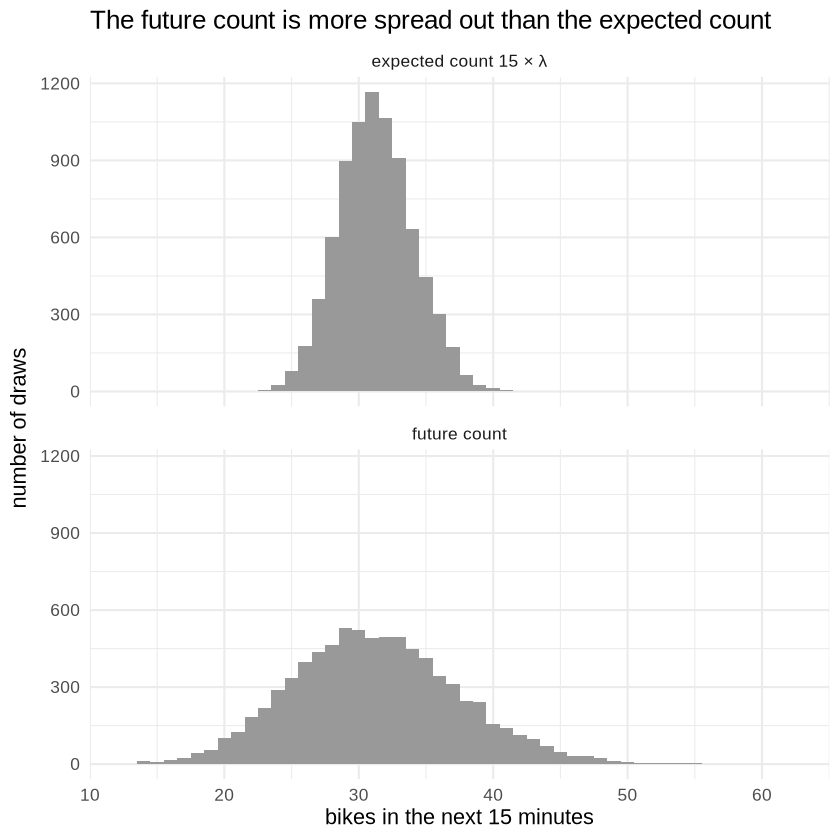

In [10]:
two_questions <- bind_rows(
  tibble(bikes = draws$mean_new, question = "expected count 15 × λ"),
  tibble(bikes = draws$y_new,    question = "future count")
)

ggplot(two_questions, aes(x = bikes)) +
  geom_histogram(binwidth = 1, fill = "grey60") +
  facet_wrap(~ question, ncol = 1) +
  labs(x = "bikes in the next 15 minutes", y = "number of draws",
       title = "The future count is more spread out than the expected count")

## 5. Preview: could the model have produced these data?

*Not on today's slides; this idea (a posterior predictive check) comes back later in the course.*

If the model is good, data simulated from it should look like the real data. For each session we simulate many new counts of the same length from the posterior (the same two steps as a prediction) and check whether the observed count lies inside the middle 90% of the simulated counts. A small `for` loop repeats this for each of the five sessions.

In [11]:
lambda_draws <- draws$lambda
check <- bikes |> mutate(lower_90 = NA, upper_90 = NA)

for (i in 1:nrow(bikes)) {
  y_rep <- rpois(length(lambda_draws), lambda = lambda_draws * bikes$minutes[i])  # new counts for session i
  check$lower_90[i] <- quantile(y_rep, 0.05)
  check$upper_90[i] <- quantile(y_rep, 0.95)
}

check |> mutate(inside = count >= lower_90 & count <= upper_90)

session,minutes,count,lower_90,upper_90,inside
<int>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>
1,10,23,13,29,TRUE
2,15,31,22,42,TRUE
3,5,9,5,16,TRUE
4,20,44,30,54,TRUE
5,10,18,13,29,TRUE


**What to see:** all five observed counts lie inside their intervals, so these data give no sign that the rate differs between sessions. With only five sessions this is weak evidence either way.

## Try this

- Use a prior that expects 5 bikes per minute with the weight of 10 minutes: Gamma(50, 10). How much does the posterior move?
- Pretend all sessions were 12 minutes long (same counts). What changes, and why?
- Predict 60 minutes instead of 15 (`t_new`). Which interval grows faster, the expected count or the future count?